# IPSD — Minggu 8: Klastering: K-Means & DBSCAN

**Mata Kuliah:** Infrastruktur dan Platform untuk Sains Data  
**Sub-CLO:** Sub-CLO-09-4-1  

## Capaian Praktikum
- Membedakan clustering berbasis centroid dan density.
- Menggunakan K-Means dan DBSCAN.
- Mengevaluasi clustering dengan silhouette dan inspeksi visual.

**Dataset:** Data sintetis `make_blobs` dengan noise tambahan.

## Alur Praktikum
- 1. Generate data dan lakukan scaling.
- 2. Jalankan K-Means untuk beberapa k.
- 3. Jalankan DBSCAN untuk beberapa eps/min_samples.
- 4. Visualisasikan label cluster dan noise.

KMeans silhouette: 0.8586929001817277
DBSCAN silhouette: 0.8586929001817277
Noise points: 0


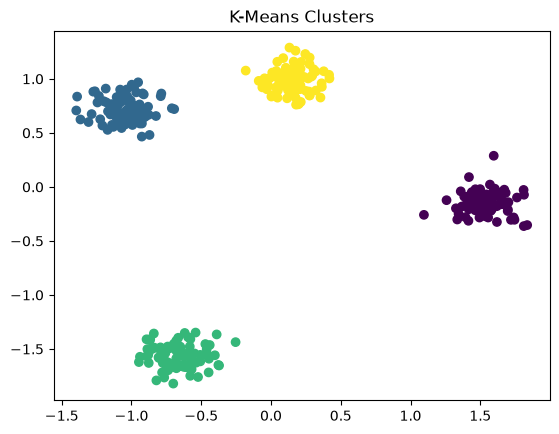

In [1]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score

X, _ = make_blobs(n_samples=350, centers=4, cluster_std=0.70, random_state=42)
X = StandardScaler().fit_transform(X)

kmeans = KMeans(n_clusters=4, random_state=42, n_init='auto').fit(X)
print('KMeans silhouette:', silhouette_score(X, kmeans.labels_))

db = DBSCAN(eps=0.35, min_samples=5).fit(X)
labels = db.labels_
mask = labels != -1
if len(set(labels[mask])) > 1:
    print('DBSCAN silhouette:', silhouette_score(X[mask], labels[mask]))
print('Noise points:', int((labels == -1).sum()))

fig, ax = plt.subplots()
ax.scatter(X[:,0], X[:,1], c=kmeans.labels_)
ax.set_title('K-Means Clusters')
plt.show()

## Latihan Terstruktur
- Tentukan k kandidat menggunakan silhouette.
- Eksperimen minimal tiga nilai eps DBSCAN.
- Jelaskan kapan DBSCAN lebih tepat daripada K-Means.

,k,silhouette,inertia
0,2,0.5032,419.1694
1,3,0.7735,76.1327
2,4,0.8587,10.3623
3,5,0.7234,9.4506
4,6,0.5793,8.4498
5,7,0.4573,7.4823
6,8,0.4557,6.9150


k terbaik menurut silhouette: 4


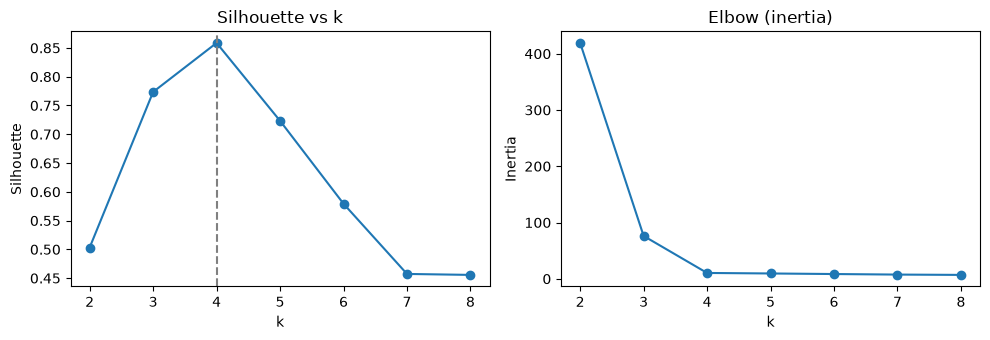

In [2]:
import numpy as np
import pandas as pd

rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=42, n_init='auto').fit(X)
    rows.append({'k': k,
                 'silhouette': silhouette_score(X, km.labels_),
                 'inertia': km.inertia_})
df_k = pd.DataFrame(rows)
display(df_k.round(4))

best_k = int(df_k.loc[df_k['silhouette'].idxmax(), 'k'])
print('k terbaik menurut silhouette:', best_k)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(df_k['k'], df_k['silhouette'], marker='o')
axes[0].axvline(best_k, ls='--', c='gray')
axes[0].set_xlabel('k'); axes[0].set_ylabel('Silhouette'); axes[0].set_title('Silhouette vs k')
axes[1].plot(df_k['k'], df_k['inertia'], marker='o')
axes[1].set_xlabel('k'); axes[1].set_ylabel('Inertia'); axes[1].set_title('Elbow (inertia)')
plt.tight_layout(); plt.show()

Silhouette tertinggi ada pada **k = 4** (≈ 0,859), lalu turun tajam pada k = 5 (≈ 0,723) dan seterusnya. Kurva inertia juga menunjukkan *elbow* di k = 4 (turun drastis dari k = 3 ke 4, lalu melandai). Hal ini konsisten dengan data yang dibangkitkan dari 4 pusat (`centers=4`). Kandidat k yang layak: **4** (terbaik) dan **3** (kedua, ≈ 0,774).

In [3]:
rows = []
for eps in [0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.50, 0.70]:
    for ms in [5, 10]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit(X).labels_
        m = lab != -1
        n_cl = len(set(lab[m]))
        sil = silhouette_score(X[m], lab[m]) if n_cl > 1 else np.nan
        rows.append({'eps': eps, 'min_samples': ms, 'n_cluster': n_cl,
                     'n_noise': int((~m).sum()), 'silhouette': sil})
df_db = pd.DataFrame(rows)
display(df_db.round(4))

,eps,min_samples,n_cluster,n_noise,silhouette
0,0.15,5,4,3,0.8609
1,0.15,10,4,4,0.8615
2,0.20,5,4,2,0.8604
3,0.20,10,4,2,0.8604
4,0.25,5,4,1,0.8595
5,0.25,10,4,1,0.8595
6,0.30,5,4,0,0.8587
7,0.30,10,4,0,0.8587
8,0.35,5,4,0,0.8587
9,0.35,10,4,0,0.8587


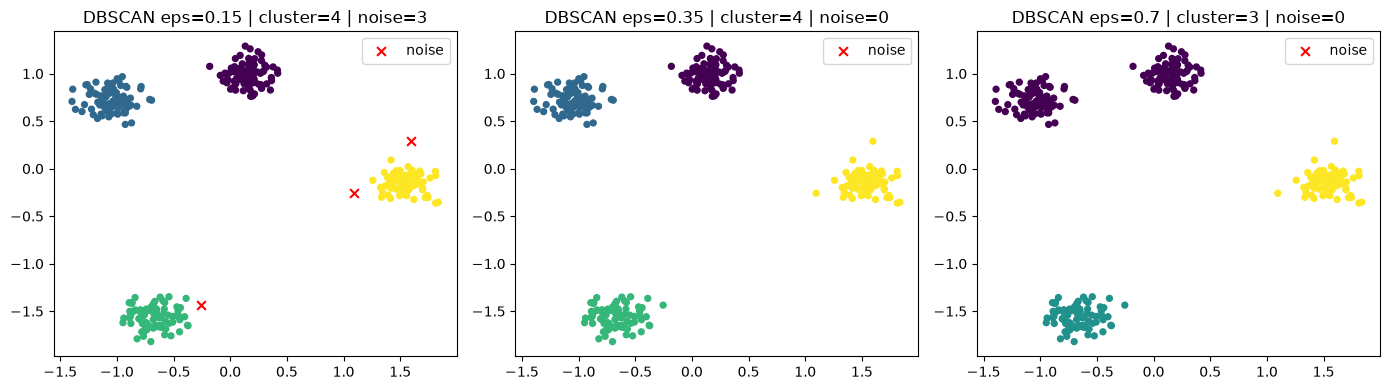

In [4]:
# Visualisasi tiga nilai eps: terlalu kecil, pas, terlalu besar
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, eps in zip(axes, [0.15, 0.35, 0.70]):
    lab = DBSCAN(eps=eps, min_samples=5).fit(X).labels_
    noise = lab == -1
    ax.scatter(X[~noise, 0], X[~noise, 1], c=lab[~noise], s=18)
    ax.scatter(X[noise, 0], X[noise, 1], c='red', marker='x', s=40, label='noise')
    ax.set_title(f'DBSCAN eps={eps} | cluster={len(set(lab[~noise]))} | noise={noise.sum()}')
    ax.legend()
plt.tight_layout(); plt.show() 


- Waktu eps kecil (0,15–0,25), ada 1–4 titik yang dianggap noise. Kemungkinan karena titik di pinggir cluster nggak punya cukup tetangga dalam radius sekecil itu. Jumlah cluster tetap 4.
- Di eps 0,30–0,50 hasilnya paling rapi: 4 cluster, noise 0, silhouette sekitar 0,859 (sama persis dengan K-Means k = 4).
- Waktu eps dibesarin jadi 0,70, dua cluster yang letaknya berdekatan jadi nyatu. Akhirnya cuma kebentuk 3 cluster dan silhouette turun ke sekitar 0,774.
- Ganti min_samples dari 5 ke 10 hampir nggak ngaruh. Mungkin karena datanya padat dan antar cluster-nya sudah terpisah jelas.

Jadi di dataset blobs ini DBSCAN dan K-Means hasilnya hampir sama. Wajar sih, karena bentuk cluster-nya bulat dan terpisah jelas, itu kondisi yang paling cocok buat K-Means. Bedanya baru kelihatan kalau bentuk datanya nggak bulat, seperti di latihan 3.

ARI K-Means (moons): 0.438
ARI DBSCAN  (moons): 1.0
Noise terdeteksi pada data + outlier: 7 dari 15 outlier yang ditambahkan


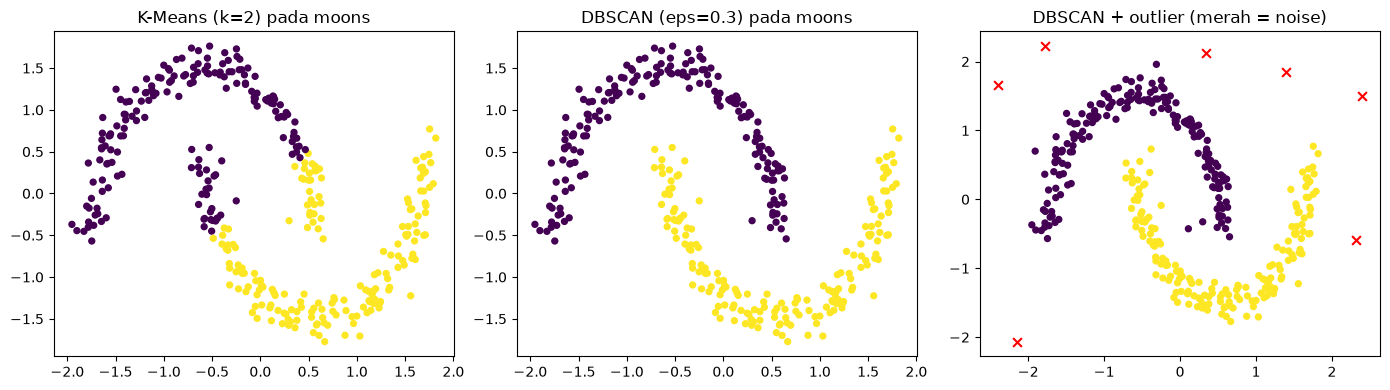

In [5]:
from sklearn.datasets import make_moons
from sklearn.metrics import adjusted_rand_score

Xm, ym = make_moons(n_samples=350, noise=0.07, random_state=42)
Xm = StandardScaler().fit_transform(Xm)

# Tambahkan outlier acak
rng = np.random.RandomState(0)
outliers = rng.uniform(-2.5, 2.5, size=(15, 2))
Xmo = np.vstack([Xm, outliers])

km_m = KMeans(n_clusters=2, random_state=42, n_init='auto').fit(Xm)
db_m = DBSCAN(eps=0.3, min_samples=5).fit(Xm)
print('ARI K-Means (moons):', round(adjusted_rand_score(ym, km_m.labels_), 3))
print('ARI DBSCAN  (moons):', round(adjusted_rand_score(ym, db_m.labels_), 3))

db_o = DBSCAN(eps=0.3, min_samples=5).fit(Xmo)
print('Noise terdeteksi pada data + outlier:', int((db_o.labels_ == -1).sum()), 'dari 15 outlier yang ditambahkan')

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].scatter(Xm[:,0], Xm[:,1], c=km_m.labels_, s=18); axes[0].set_title('K-Means (k=2) pada moons')
axes[1].scatter(Xm[:,0], Xm[:,1], c=db_m.labels_, s=18); axes[1].set_title('DBSCAN (eps=0.3) pada moons')
nz = db_o.labels_ == -1
axes[2].scatter(Xmo[~nz,0], Xmo[~nz,1], c=db_o.labels_[~nz], s=18)
axes[2].scatter(Xmo[nz,0], Xmo[nz,1], c='red', marker='x', s=40)
axes[2].set_title('DBSCAN + outlier (merah = noise)')
plt.tight_layout(); plt.show()

Di data bulan sabit, K-Means cuma dapat ARI sekitar 0,44 karena dia motong datanya lurus di tengah. DBSCAN dengan eps = 0,3 dapat ARI 1,0, artinya kedua bulan sabit berhasil dipisah dengan pas. DBSCAN juga bisa nandain outlier yang kepisah sebagai noise (7 dari 15 outlier tambahan; sisanya kebetulan jatuh dekat bulan sabit), sedangkan K-Means tetap maksa semua titik masuk ke salah satu cluster.

Kapan DBSCAN lebih cocok daripada K-Means:

Bentuk cluster-nya nggak bulat (sabit, cincin, memanjang), karena DBSCAN bekerja berdasarkan kepadatan titik, bukan jarak ke centroid.
Datanya ada outlier atau noise yang mau dipisahin, bukan dimasukin ke cluster.
Jumlah cluster belum diketahui di awal, soalnya DBSCAN nentuin sendiri dari datanya.

Kapan K-Means masih lebih baik: kalau cluster-nya bulat dengan ukuran dan kepadatan yang mirip, datanya besar (K-Means lebih cepat), dan jumlah cluster sudah diketahui. DBSCAN agak susah kalau kepadatan antar cluster beda jauh, dan hasilnya sensitif sama pilihan eps (k-distance plot bisa bantu nyari nilainya).

## Luaran
Notebook + tabel eksperimen parameter + prompt log L2.

**Bukti AI/validasi:** Prompt log; desain eksperimen.

## Prompt Log — wajib
Isi minimal 2 interaksi yang benar-benar Anda gunakan.

| No | Tujuan Prompt | Prompt | Ringkasan Respons AI | Keputusan Saya / Apa yang Dipakai | Verifikasi |
|---|---|---|---|---|---|
|1|Memahami cara mengimplementasikan K-Means dan DBSCAN|bagaimana cara mengimplemtasikan klasterin kmeans & dbscan|AI menjelaskan langkah umum (scaling, pilih parameter, fit model, evaluasi), memberi contoh kode K-Means (mencari k dengan silhouette) dan DBSCAN (eps, min_samples, label -1 sebagai noise, k-distance plot), serta tabel perbandingan keduanya|Saya pakai penjelasan dan alur kodenya untuk memahami kode latihan di notebook|Menjalankan ulang notebook dan mencocokkan hasilnya (silhouette, jumlah cluster, jumlah noise) dengan penjelasan AI|
|2|Membuat penjelasan hasil latihan lebih mudah dipahami|ubah semua bahasa yg aku kirim sebelumnya menjadi bahasa yg mudah dipahmi, jgn ada tambahan data atau mengubah atau mngurangi, cukup ubah bahasanya|AI menulis ulang dua teks (analisis eps DBSCAN dan hasil latihan 3) dengan bahasa yang lebih sederhana tanpa mengubah isi dan angkanya|Saya pakai teks hasil tulis ulang tersebut di bagian interpretasi notebook|Membandingkan angka di teks (0,859; 0,774; ARI 0,44 dan 1,0; 7 dari 15 outlier) dengan output notebook saat dijalankan|

## Refleksi Singkat
1. Bagian apa yang paling terbantu oleh AI?  
cara jelasin datanya, terus juga ngeubah bahasa aku yg ga terlalu dipahami jadi ahasa yg mudah dipahami. trus juga koreksi kode
2. Bagian apa yang tetap harus Anda putuskan sendiri?  
nilai k, eps yg dipake berdasarkan hasil notebook, ngecek apkh angka di penjelasn cocok dgn output waktu notebook dijalanin sma ngisi prompt log
3. Apa satu keterbatasan/risiko respons AI yang Anda temukan?penjelasan AI kya yakin, padahal harus dicek lagi. contohnya, di data blobs hasil DBSCAN dan K-Means hampir sama dan hampir ga ada noise, karena deskripsi tugas nyebut ada noise tambahan tapi kodenya tidak menambahkannya. selain itu, DBSCAN hanya menandai 7 dari 15 outlier tambahan sebagai noise, jadi kesimpulan “DBSCAN bisa mendeteksi outlier” ga boleh dianggap berlaku untuk semua titik.